# NHL: предсказать успешность команды в следующем сезоне

**Автор:** Железко Артём   
**Дата:** 12.10.2026 
**Использованные источники и инструменты:** Scrape This Site — Hockey Teams (https://www.scrapethissite.com/pages/forms/); Python, pandas, numpy, scikit-learn, matplotlib; Claude (каюсь, он мне помогал разобраться с некоторыми заданиями и немного помог с scraper, редактировал текст, делал его читабельным и красивым).

In [17]:
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42
Path("data").mkdir(exist_ok=True)

## Раздел 1. Сбор и понимание данных
### 1.1. Соберите и сохраните данные

In [18]:
#Лучше с впн
from __future__ import annotations

from io import StringIO
import time
import sys
from pathlib import Path

import pandas as pd
import requests

BASE_URL = "https://www.scrapethissite.com/pages/forms/"
PAGE_COUNT = 24
OUTPUT_CSV = Path("data/hockey_raw.csv")
OUTPUT_XLSX = Path("data/hockey_raw.xlsx")

COLUMNS = [
    "team_name",
    "year",
    "wins",
    "losses",
    "ot_losses",
    "win_percentage",
    "goals_for",
    "goals_against",
    "goal_difference",
]

RENAME = {
    "Team Name": "team_name",
    "Year": "year",
    "Wins": "wins",
    "Losses": "losses",
    "OT Losses": "ot_losses",
    "Win %": "win_percentage",
    "Goals For (GF)": "goals_for",
    "Goals Against (GA)": "goals_against",
    "+ / -": "goal_difference",
}

NUMERIC_COLUMNS = [
    "year", "wins", "losses", "ot_losses", "win_percentage",
    "goals_for", "goals_against", "goal_difference",
]


def main() -> None:
    session = requests.Session()
    session.headers.update({
        "User-Agent": (
            "Mozilla/5.0 (compatible; educational-dataset-collector/1.0)"
        )
    })

    frames = []
    for page in range(1, PAGE_COUNT + 1):
        url = f"{BASE_URL}?page_num={page}"
        print(f"[{page}/{PAGE_COUNT}] Загружаю {url}")

        response = session.get(url, timeout=30)
        response.raise_for_status()



        tables = pd.read_html(StringIO(response.text))
        if not tables:
            raise RuntimeError(f"На странице {page} не найдена таблица.")

        # Ищем таблицу по ожидаемым заголовкам, чтобы не взять навигацию.
        table = None
        for candidate in tables:
            normalized = {str(c).strip() for c in candidate.columns}
            if {"Team Name", "Year", "Wins", "Losses"}.issubset(normalized):
                table = candidate.copy()
                break

        if table is None:
            raise RuntimeError(
                f"Не удалось определить таблицу с командами на странице {page}."
            )

        table.columns = [str(c).strip() for c in table.columns]
        table = table.rename(columns=RENAME)

        missing = [c for c in COLUMNS if c not in table.columns]
        if missing:
            raise RuntimeError(
                f"На странице {page} отсутствуют столбцы: {missing}"
            )

        table = table[COLUMNS]
        table["source_page"] = page
        frames.append(table)

        time.sleep(0.25)  # Небольшая пауза между запросами.

    data = pd.concat(frames, ignore_index=True)

    # Приводим числа к числовым типам; пустые OT Losses остаются NaN.
    for column in NUMERIC_COLUMNS:
        data[column] = pd.to_numeric(data[column], errors="coerce")

    # Удаляем только полностью дублирующиеся строки данных, если они есть.
    data = data.drop_duplicates(subset=COLUMNS).reset_index(drop=True)

    # UTF-8 с BOM удобно открывается в Excel.
    data.to_csv(OUTPUT_CSV, index=False, encoding="utf-8-sig")
    data.to_excel(OUTPUT_XLSX, index=False)

    print("\nГотово!")
    print(f"Строк: {len(data)}")
    print(f"Столбцов: {len(data.columns)}")
    print(f"CSV:   {OUTPUT_CSV.resolve()}")
    print(f"Excel: {OUTPUT_XLSX.resolve()}")
    print("\nПервые 5 строк:")
    print(data.head().to_string(index=False))
    print("\nПропуски по столбцам:")
    print(data.isna().sum().to_string())


if __name__ == "__main__":
    try:
        main()
    except requests.RequestException as exc:
        print(f"Ошибка сетевого запроса: {exc}", file=sys.stderr)
        sys.exit(1)
    except Exception as exc:
        print(f"Ошибка сбора данных: {exc}", file=sys.stderr)
        sys.exit(1)

[1/24] Загружаю https://www.scrapethissite.com/pages/forms/?page_num=1
[2/24] Загружаю https://www.scrapethissite.com/pages/forms/?page_num=2
[3/24] Загружаю https://www.scrapethissite.com/pages/forms/?page_num=3
[4/24] Загружаю https://www.scrapethissite.com/pages/forms/?page_num=4
[5/24] Загружаю https://www.scrapethissite.com/pages/forms/?page_num=5
[6/24] Загружаю https://www.scrapethissite.com/pages/forms/?page_num=6
[7/24] Загружаю https://www.scrapethissite.com/pages/forms/?page_num=7
[8/24] Загружаю https://www.scrapethissite.com/pages/forms/?page_num=8
[9/24] Загружаю https://www.scrapethissite.com/pages/forms/?page_num=9
[10/24] Загружаю https://www.scrapethissite.com/pages/forms/?page_num=10
[11/24] Загружаю https://www.scrapethissite.com/pages/forms/?page_num=11
[12/24] Загружаю https://www.scrapethissite.com/pages/forms/?page_num=12
[13/24] Загружаю https://www.scrapethissite.com/pages/forms/?page_num=13
[14/24] Загружаю https://www.scrapethissite.com/pages/forms/?page_num

**Ответ 1.1**

Источник: https://www.scrapethissite.com/pages/forms/, страницы `?page_num=1` … `24`. Функция `scrape_all()` (тот же код в `scrape_hockey.py`) для каждой страницы читает таблицы через `pd.read_html`, выбирает нужную по заголовкам, переименовывает столбцы, добавляет `source_page` и приводит числа к числовому типу. Пустой `OT Losses` остаётся NaN.

Обработано 24 страницы и 582 строки: 23 страницы по 25 строк и последняя из 7. Сбор не ограничился первой страницей: на ней 25 строк, а в таблице 582, `source_page` принимает значения 1–24, годы 1990–2011. Число страниц в скрипте задано константой, я сверил его с пагинацией на сайте (24 ссылки).

Таблица записана в `data/hockey_raw.csv`, прочитана заново и сравнена с исходной через `assert_frame_equal`. Дальше ноутбук читает только этот файл. Дата сбора пишется в `COLLECTION_DATE`; если ноутбук запущен без сети, берётся ранее сохранённая выгрузка и дату нужно вписать вручную.

### 1.2. Проверьте качество таблицы

In [19]:
df = pd.read_csv("data/hockey_raw.csv")
print(df.dtypes.to_string(), "\n")
print("пропуски:\n", df.isna().sum().to_string(), "\n")
print("дублей пары team-year:", df.duplicated(["team_name", "year"]).sum())

# Проверка 1: goal_difference == goals_for - goals_against
print("несоответствий goal_difference:", int((df.goal_difference != df.goals_for - df.goals_against).sum()))

# Проверка 2: какое число игр подразумевает win_percentage? wins / win_percentage
df["games_implied"] = df.wins / df.win_percentage
df["w_l_otl"] = df.wins + df.losses + df.ot_losses.fillna(0)
season_games = df.groupby("year").games_implied.median().round()
df["games_season"] = df.year.map(season_games)
print("\nдлина сезона (игр, по wins/win_percentage, медиана по году):")
print(season_games.astype(int).to_string())
dev = (df.games_implied - df.games_season).abs()
print("\nмакс. отклонение wins/win_percentage от длины сезона:", dev.max(),
      "| строк с отклонением > 1 игры:", int((dev > 1).sum()))

# Проверка 3: wins+losses+ot_losses против длины сезона -> скрытые ничьи
df["hidden_ties"] = df.games_season - df.w_l_otl
print("\nсредние «скрытые» игры (ничьи), которых нет в таблице, по годам:")
print(df.groupby("year").hidden_ties.mean().round(1).to_string())

# Проверка 4: структура по годам
by_year = df.groupby("year").agg(teams=("team_name", "nunique"), ot_missing=("ot_losses", lambda s: s.isna().mean()),
                                  mean_wr=("win_percentage", "mean"), median_wr=("win_percentage", "median"))
display(by_year.round(3))
all_years = set(range(df.year.min(), df.year.max() + 1))
print("отсутствующие годы:", sorted(all_years - set(df.year)))

team_name           object
year                 int64
wins                 int64
losses               int64
ot_losses          float64
win_percentage     float64
goals_for            int64
goals_against        int64
goal_difference      int64
source_page          int64 

пропуски:
 team_name            0
year                 0
wins                 0
losses               0
ot_losses          224
win_percentage       0
goals_for            0
goals_against        0
goal_difference      0
source_page          0 

дублей пары team-year: 0
несоответствий goal_difference: 0

длина сезона (игр, по wins/win_percentage, медиана по году):
year
1990    80
1991    80
1992    84
1993    84
1994    48
1995    82
1996    82
1997    82
1998    82
1999    82
2000    82
2001    82
2002    82
2003    82
2005    82
2006    82
2007    82
2008    82
2009    82
2010    82
2011    82

макс. отклонение wins/win_percentage от длины сезона: 0.18867924528302638 | строк с отклонением > 1 игры: 0

средние «скрытые» 

,teams,ot_missing,mean_wr,median_wr
year,,,,
1990,21,1.0,0.433,0.425
1991,22,1.0,0.433,0.444
1992,24,1.0,0.450,0.476
1993,26,1.0,0.436,0.464
1994,26,1.0,0.440,0.428
1995,26,1.0,0.436,0.433
1996,26,1.0,0.432,0.427
1997,26,1.0,0.423,0.427
1998,27,1.0,0.427,0.415


отсутствующие годы: [2004]


**Ответ 1.2**

Все столбцы числовые, кроме `team_name`. Пропуски только в `ot_losses`: 224 строки из 582, и все они относятся к 1990–1998 годам, когда этого показателя ещё не было. Дублей пары `team_name`–`year` нет.

Проверки:
1. `goal_difference` равен `goals_for − goals_against` во всех строках.
2. `wins / win_percentage` даёт целое число игр сезона: 80 в 1990 и 1991, 84 в 1992 и 1993, 48 в 1994 (сокращённый сезон), дальше 82. Сумма `wins + losses + ot_losses` до 2005 года меньше длины сезона в среднем на 10 игр, потому что ничьи в таблице не показаны. С 2005 расхождения нет. Значит, до 2005 `win_percentage` считается от всех игр, включая ничьи, и в среднем равен 0.43; с 2005 он ровно 0.500.
3. В данных нет 2004 года (сезон не проводился). Число команд растёт с 21 до 30.

Решения. `ot_losses` я не заменяю нулём: пропуск здесь означает, что показатель не вёлся. Его заполняют медианой с индикатором пропуска внутри `Pipeline`, по train. Из-за разной длины сезона и сдвига среднего `win_percentage` в 4.3 я проверяю признаки «на игру» и «относительно лиги в сезоне».

## Раздел 2. Построение задачи и корректность проверки
### 2.1. Постройте target

In [20]:
raw = pd.read_csv("data/hockey_raw.csv")

# Медиана будущего сезона — по ПОЛНОЙ исходной таблице (до отбора пар)
median_by_year = raw.groupby("year").win_percentage.median().rename("median_next")

nxt = raw[["team_name", "year", "win_percentage"]].copy()
nxt["year"] = nxt["year"] - 1            # строка сезона t+1 привязывается к сезону t
nxt = nxt.rename(columns={"win_percentage": "win_percentage_next"})

pairs = raw.merge(nxt, on=["team_name", "year"], how="inner")      # одна и та же команда, ровно t+1
pairs["target_year"] = pairs["year"] + 1
pairs = pairs.merge(median_by_year, left_on="target_year", right_index=True, how="left")
pairs["target"] = (pairs.win_percentage_next > pairs.median_next).astype(int)   # строго больше медианы
assert not pairs.duplicated(["team_name", "year"]).any()

paired_keys = pairs[["team_name", "year"]].assign(has_pair=True)
excluded = raw.merge(paired_keys, on=["team_name", "year"], how="left").query("has_pair != True")
print("исходных строк:", len(raw), "| пар:", len(pairs), "| исключено строк:", len(excluded))
print("исключено по годам t:", excluded.groupby("year").size().to_dict())
ties = pairs[pairs.win_percentage_next == pairs.median_next]
print("равенств будущей медиане:", len(ties), "(для них target = 0)")
print("доля класса 1 во всех парах:", round(pairs.target.mean(), 3))
display(excluded[excluded.year != 2011][["team_name", "year"]])

исходных строк: 582 | пар: 516 | исключено строк: 66
исключено по годам t: {1992: 1, 1994: 1, 1995: 1, 1996: 1, 2003: 30, 2005: 1, 2010: 1, 2011: 30}
равенств будущей медиане: 23 (для них target = 0)
доля класса 1 во всех парах: 0.484


,team_name,year
51,Minnesota North Stars,1992
111,Quebec Nordiques,1994
144,Winnipeg Jets,1995
155,Hartford Whalers,1996
342,Mighty Ducks of Anaheim,2003
343,Atlanta Thrashers,2003
344,Boston Bruins,2003
345,Buffalo Sabres,2003
346,Calgary Flames,2003
347,Carolina Hurricanes,2003


In [21]:
# Ручная проверка на двух содержательно разных примерах: (а) пример у границы медианы, (б) явное превышение
pairs["margin"] = pairs.win_percentage_next - pairs.median_next
near = pairs.loc[pairs.margin.abs().idxmin()]
far = pairs.loc[pairs.margin.idxmax()]

def check(row):
    t, y = row.team_name, int(row.year)
    cur = raw[(raw.team_name == t) & (raw.year == y)].iloc[0]
    nx = raw[(raw.team_name == t) & (raw.year == y + 1)].iloc[0]
    season = np.sort(raw[raw.year == y + 1].win_percentage.values)
    med = np.median(season)                 # независимый пересчёт медианы вручную через numpy
    print(f"{t}: сезон {y} (win_percentage={cur.win_percentage}) -> {y+1} (win_percentage={nx.win_percentage})")
    print(f"  команд в {y+1}: {len(season)}, медиана win_percentage = {med}")
    print(f"  {nx.win_percentage} > {med} ? {nx.win_percentage > med} -> target должен быть {int(nx.win_percentage > med)}; в таблице pairs: {int(row.target)}")
    assert int(nx.win_percentage > med) == int(row.target)

check(near); print(); check(far)

New Jersey Devils: сезон 1991 (win_percentage=0.475) -> 1992 (win_percentage=0.476)
  команд в 1992: 24, медиана win_percentage = 0.476
  0.476 > 0.476 ? False -> target должен быть 0; в таблице pairs: 0

Detroit Red Wings: сезон 1994 (win_percentage=0.688) -> 1995 (win_percentage=0.756)
  команд в 1995: 26, медиана win_percentage = 0.433
  0.756 > 0.433 ? True -> target должен быть 1; в таблице pairs: 1


**Ответ 2.1**

Из 582 исходных строк получилось 516 пар. Исключено 66 строк, у которых нет той же команды в сезоне t+1: 30 за 2011 год (нет 2012), 30 за 2003 (нет 2004) и 6 одиночных строк с изменением названия: Minnesota North Stars (1992), Quebec Nordiques (1994), Winnipeg Jets (1995), Hartford Whalers (1996), Mighty Ducks of Anaheim (2005), Atlanta Thrashers (2010). Скорее всего, это переезды и переименования, но это знание не из таблицы. По условию пары строятся по одинаковому названию, поэтому эти строки в пары не попали.

Медиана считалась по всей таблице сезона t+1, включая команды без пары. Target равен 1, если `win_percentage_next` строго больше медианы. Равенство медиане встретилось 23 раза, во всех этих случаях target = 0. Доля класса 1 по всем парам 0.484.

Ручная проверка с независимым пересчётом медианы через numpy:
- New Jersey Devils, 1991 → 1992: 0.476 при медиане 0.476. Строгого превышения нет, target = 0, как в таблице. Это один из 23 случаев равенства.
- Detroit Red Wings, 1994 → 1995 (сокращённый сезон из 48 игр): 0.756 при медиане 0.433 по 26 командам, target = 1, как в таблице.

### 2.2. Подготовьте временную проверку

In [22]:
def split_of(y):
    return "train" if y <= 2005 else ("validation" if y <= 2008 else ("test" if y <= 2011 else "other"))
pairs["split"] = pairs.target_year.map(split_of)

summary = pairs.groupby("split").agg(
    target_years=("target_year", lambda s: sorted(s.unique().tolist())),
    n=("target", "size"), n_class1=("target", "sum"), share_class1=("target", "mean")).round(3)
summary = summary.loc[["train", "validation", "test"]]
display(summary)

train = pairs[pairs.split == "train"].copy()
val   = pairs[pairs.split == "validation"].copy()
test  = pairs[pairs.split == "test"].copy()
assert train.target_year.max() < val.target_year.min() and val.target_year.max() < test.target_year.min()
print("пересечений по target_year нет; max train =", train.target_year.max(),
      "| min val =", val.target_year.min(), "| min test =", test.target_year.min())
print("годы признаков (t): train", int(train.year.min()), "-", int(train.year.max()),
      "| val", sorted(val.year.unique().tolist()), "| test", sorted(test.year.unique().tolist()))

,target_years,n,n_class1,share_class1
split,,,,
train,"[1991, 1992, 1993, 1994, 1995, 1996, 1997, 199...",338,166,0.491
validation,"[2006, 2007, 2008]",89,42,0.472
test,"[2009, 2010, 2011]",89,42,0.472


пересечений по target_year нет; max train = 2003 | min val = 2006 | min test = 2009
годы признаков (t): train 1990 - 2002 | val [2005, 2006, 2007] | test [2008, 2009, 2010]


**Ответ 2.2**

| часть | target_year | пар | класс 1 | доля класса 1 |
|---|---|---|---|---|
| train | 1991–2003 | 338 | 166 | 0.491 |
| validation | 2006, 2007, 2008 | 89 | 42 | 0.472 |
| test | 2009, 2010, 2011 | 89 | 42 | 0.472 |

В train нет 2004 и 2005 годов: сезона 2004 нет в данных, а для пары с целевым 2005 не хватает признаков 2004. Годы признаков (t): train 1990–2002, validation 2005–2007, test 2008–2010. Весь train относится к эпохе до локаута, а validation и test к эпохе после него, и это важно для 3.2 и 4.3.

Недоступны модели в момент прогноза `win_percentage_next` и `median_next`. Это же касается производных `margin` и `delta_wr`. В списки признаков они не входят.

Случайное перемешивание ответило бы на другой вопрос. В train попали бы пары из «будущего» относительно test-строк, а признаки сезона t одной строки совпадают с результатом сезона t+1 соседней строки той же команды, так что информация о target просачивалась бы через соседей. Оценка показала бы, насколько хорошо модель восстанавливает пропущенный сезон внутри известной истории, а не как она предсказывает следующий год. Временное разбиение отвечает на второй вопрос, и только оно показывает проблему сдвига между эпохами.

## Раздел 3. Исследовательский анализ
### 3.1. Сформулируйте вопросы к данным

**Ответ 3.1** (вопросы записаны до построения графиков)

**Вопрос 1.** Насколько текущий `win_percentage` связан с тем, окажется ли команда выше медианы в следующем сезоне? Ожидаю, что доля target=1 растёт по квинтилям `win_percentage`, а корреляция с будущим значением умеренная, около 0.5, из-за возврата к среднему: сильные команды часто теряют очки, слабые прибавляют. Если почти весь сигнал в `win_percentage` и `goal_difference`, хватит простой линейной модели на малом числе признаков, а планкой для неё станет один `win_percentage`.

**Вопрос 2.** Одинаковы ли шкалы признаков в разные эпохи: средний `win_percentage`, голы за игру, `ot_losses`, длина сезона? Ожидаю, что до 2005 года из-за ничьих средний `win_percentage` ниже 0.5, а после ровно 0.5, и что `ot_losses` после 2005 заметно больше. Тогда абсолютные признаки дадут сдвиг на validation и test, и придётся перейти к признакам «на игру» и относительным к лиге, а `ot_losses` использовать осторожно.

### 3.2. Проведите исследовательский анализ

C:\Users\artem\AppData\Local\Temp\ipykernel_2584\3186546399.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  q1 = tr.groupby("wr_quintile").agg(n=("target", "size"), share_target1=("target", "mean"),


,n,share_target1,mean_wr_next
wr_quintile,,,
"(0.118, 0.345]",68,0.147,0.355
"(0.345, 0.415]",74,0.324,0.412
"(0.415, 0.463]",65,0.569,0.458
"(0.463, 0.524]",68,0.603,0.463
"(0.524, 0.756]",63,0.857,0.514


corr(win_rate_t, win_rate_t+1) на train: 0.561
corr(goal_diff_t, win_rate_t+1) на train: 0.555


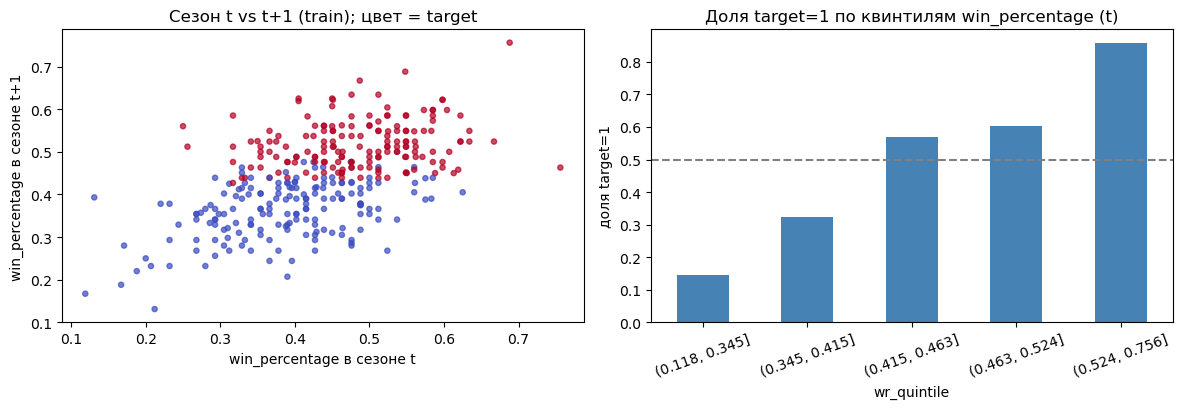

In [23]:
# Вопрос 1: насколько текущий win_percentage связан с будущим классом? (только train)
tr = train.copy()
tr["wr_quintile"] = pd.qcut(tr.win_percentage, 5)
q1 = tr.groupby("wr_quintile").agg(n=("target", "size"), share_target1=("target", "mean"),
                                    mean_wr_next=("win_percentage_next", "mean")).round(3)
display(q1)
print("corr(win_rate_t, win_rate_t+1) на train:", round(tr[["win_percentage", "win_percentage_next"]].corr().iloc[0, 1], 3))
print("corr(goal_diff_t, win_rate_t+1) на train:", round(tr[["goal_difference", "win_percentage_next"]].corr().iloc[0, 1], 3))

_, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(tr.win_percentage, tr.win_percentage_next, c=tr.target, cmap="coolwarm", s=14, alpha=.7)
ax[0].set_xlabel("win_percentage в сезоне t"); ax[0].set_ylabel("win_percentage в сезоне t+1")
ax[0].set_title("Сезон t vs t+1 (train); цвет = target")
q1.share_target1.plot.bar(ax=ax[1], color="steelblue"); ax[1].axhline(.5, color="gray", ls="--")
ax[1].set_ylabel("доля target=1"); ax[1].set_title("Доля target=1 по квинтилям win_percentage (t)")
ax[1].set_xticklabels([str(i) for i in q1.index], rotation=20)
plt.tight_layout(); plt.show()

,mean_win_rate,goals_per_game,ot_known,mean_ot_losses
year,,,,
1990,0.433,3.455,0.0,NaN
1991,0.433,3.479,0.0,NaN
1992,0.450,3.626,0.0,NaN
1993,0.436,3.242,0.0,NaN
1994,0.440,2.986,0.0,NaN
1995,0.436,3.143,0.0,NaN
1996,0.432,2.916,0.0,NaN
1997,0.423,2.638,0.0,NaN
1998,0.427,2.633,0.0,NaN


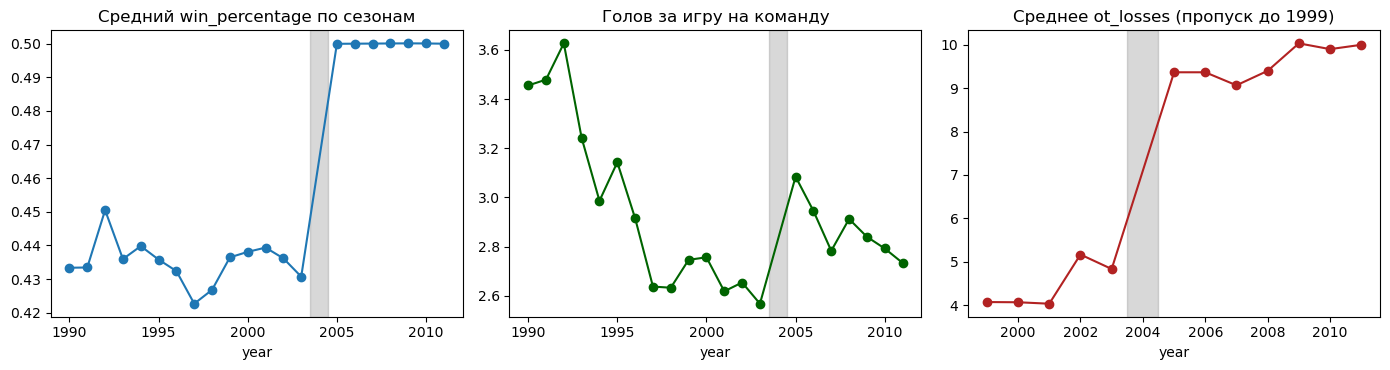

Самые большие взлёты win_percentage:


,team_name,year,win_percentage,win_percentage_next,median_next,target
36,Quebec Nordiques,1991,0.250,0.560,0.476,1
360,Pittsburgh Penguins,2005,0.268,0.573,0.518,1
123,Dallas Stars,1995,0.317,0.585,0.427,1


Самые большие падения win_percentage:


,team_name,year,win_percentage,win_percentage_next,median_next,target
124,Detroit Red Wings,1995,0.756,0.463,0.427,1
358,Philadelphia Flyers,2005,0.549,0.268,0.518,0
231,Florida Panthers,1999,0.524,0.268,0.445,0


,0,21,43,68,94,120,146,172,198,226,254,284,314,344,374,404,434,464,494,524,553
year,1990.00,1991.00,1992.000,1993.0,1994.000,1995.000,1996.000,1997.000,1998.000,1999.000,2000.000,2001.000,2002.000,2003.0,2005.000,2006.000,2007.0,2008.000,2009.000,2010.000,2011.000
wins,44.00,36.00,51.000,42.0,27.000,40.000,26.000,39.000,39.000,24.000,36.000,43.000,36.000,41.0,29.000,35.000,41.0,53.000,39.000,46.000,49.000
losses,24.00,32.00,26.000,29.0,18.000,31.000,47.000,30.000,30.000,33.000,30.000,24.000,31.000,19.0,37.000,41.000,29.0,19.000,30.000,25.000,29.000
ot_losses,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.000,8.000,9.000,4.000,7.0,16.000,6.000,12.0,10.000,13.000,11.000,4.000
win_percentage,0.55,0.45,0.607,0.5,0.562,0.488,0.317,0.476,0.476,0.293,0.439,0.524,0.439,0.5,0.354,0.427,0.5,0.646,0.476,0.561,0.598
goal_difference,35.00,-5.00,64.000,37.0,23.000,13.000,-66.000,27.000,33.000,-38.000,-22.000,35.000,8.000,21.0,-36.000,-70.000,-10.0,78.000,6.000,51.000,67.000


In [24]:
# Вопрос 2: одинакова ли «шкала» win_percentage / голов / пропусков по эпохам? (вся raw-таблица: описание данных, не target)
raw["games_season"] = raw.year.map((raw.wins / raw.win_percentage).groupby(raw.year).median().round())
raw["gf_pg"] = raw.goals_for / raw.games_season
era = raw.groupby("year").agg(mean_win_rate=("win_percentage", "mean"), goals_per_game=("gf_pg", "mean"),
                              ot_known=("ot_losses", lambda s: s.notna().mean()),
                              mean_ot_losses=("ot_losses", "mean"))
display(era.round(3))
_, ax = plt.subplots(1, 3, figsize=(14, 3.8))
era.mean_win_rate.plot(ax=ax[0], marker="o"); ax[0].set_title("Средний win_percentage по сезонам")
era.goals_per_game.plot(ax=ax[1], marker="o", color="darkgreen"); ax[1].set_title("Голов за игру на команду")
era.mean_ot_losses.plot(ax=ax[2], marker="o", color="firebrick"); ax[2].set_title("Среднее ot_losses (пропуск до 1999)")
for a in ax: a.axvspan(2003.5, 2004.5, color="gray", alpha=.3)   # сезон-локаут 2004/05 отсутствует
plt.tight_layout(); plt.show()

# Конкретные наблюдения на уровне команды/сезона
big = pairs.assign(delta=pairs.win_percentage_next - pairs.win_percentage)
cols = ["team_name", "year", "win_percentage", "win_percentage_next", "median_next", "target"]
print("Самые большие взлёты win_percentage:"); display(big.nlargest(3, "delta")[cols])
print("Самые большие падения win_percentage:"); display(big.nsmallest(3, "delta")[cols])
display(raw[raw.team_name == "Boston Bruins"].sort_values("year")[["year", "wins", "losses", "ot_losses", "win_percentage", "goal_difference"]].T)

**Ответ 3.2**

**Вопрос 1.** На train доля target=1 по квинтилям `win_percentage` такая: 0.147, 0.324, 0.569, 0.603, 0.857. Корреляция `win_percentage` с будущим значением 0.561, у `goal_difference` 0.555. Сигнал есть, но облако на диаграмме широкое: в верхнем квинтиле 14% команд всё равно оказываются ниже медианы. Резкие улучшения: Quebec Nordiques 1991 (0.250 → 0.560) и Pittsburgh Penguins 2005 (0.268 → 0.573). Резкие падения: Detroit Red Wings 1995 (0.756 → 0.463), Philadelphia Flyers 2005 (0.549 → 0.268), Florida Panthers 1999 (0.524 → 0.268). У Boston Bruins `win_percentage` за год менялся на 0.17: 0.646 в 2008 и 0.476 в 2009.
Ограничения: это корреляции на одном train, не причинность; второй и третий квинтили почти не различаются (0.569 и 0.603); `win_percentage` и `goal_difference` дублируют друг друга; target зависит от медианы конкретного года, а не от абсолютного порога.

**Вопрос 2.** Средний `win_percentage` в 1990–2003 годах 0.42–0.45, с 2005 ровно 0.500. Голов за игру на команду было около 3.5 в 1990–92, около 2.6 в 2003, 3.09 в 2005 и около 2.7 к 2011. Среднее `ot_losses` 4–5 в 1999–2003 и 9–10 после 2005. Ожидание подтвердилось: train и validation/test лежат в разных шкалах, а абсолютные `win_percentage`, голы и `ot_losses` дрейфуют.
Ограничения: причины сдвига (отмена ничьих, правила после локаута) известны мне не из таблицы, в данных виден только сам сдвиг; сезонов всего 21; графики описывают лигу в среднем, а не отдельные команды.

## Раздел 4. Модели и эксперименты
### 4.1. Постройте ориентиры

In [25]:
y_tr, y_va = train.target, val.target

dummy = DummyClassifier(strategy="prior").fit(train[["win_percentage"]], y_tr)
p_dummy_va = dummy.predict_proba(val[["win_percentage"]])[:, 1]
auc_dummy = roc_auc_score(y_va, p_dummy_va)
auc_wr = roc_auc_score(y_va, val.win_percentage)       # текущий win_percentage как score ранжирования

print(f"доля класса 1 в train: {y_tr.mean():.3f}; константная вероятность: {p_dummy_va[0]:.3f}")
print(f"константный baseline:  val ROC-AUC = {auc_dummy:.4f}")
print(f"win_rate_t как score:  val ROC-AUC = {auc_wr:.4f}")

доля класса 1 в train: 0.491; константная вероятность: 0.491
константный baseline:  val ROC-AUC = 0.5000
win_rate_t как score:  val ROC-AUC = 0.7568


**Ответ 4.1**

Константный baseline (`DummyClassifier(strategy="prior")`, доля класса 1 в train 0.491) даёт ROC-AUC на validation 0.5000: все объекты получают одну и ту же вероятность. Любая модель с AUC не выше этого значения ничего не выучила.

Текущий `win_percentage` как score даёт 0.7568. Эта планка заметно выше: модель, которая не обгоняет одну известную величину («как команда сыграла в этом сезоне»), не оправдывает усложнения.

### 4.2. Постройте первую модель

In [26]:
BASE_FEATS = ["win_percentage", "goal_difference", "goals_for", "goals_against", "ot_losses"]

def make_pipe(C=1.0):
    return Pipeline([
        ("imp", SimpleImputer(strategy="median", add_indicator=True)),   # пропуски ot_losses + индикатор пропуска
        ("sc", StandardScaler()),
        ("lr", LogisticRegression(C=C, max_iter=2000, random_state=RANDOM_STATE)),
    ])

pipe = make_pipe().fit(train[BASE_FEATS], y_tr)           # всё обучение — только train
p_va = pipe.predict_proba(val[BASE_FEATS])[:, 1]
auc_lr = roc_auc_score(y_va, p_va)
coefs = pd.Series(pipe.named_steps["lr"].coef_[0],
                  index=BASE_FEATS + ["ot_losses_missing"]).round(3)
print(f"LogReg (A, базовые признаки): val ROC-AUC = {auc_lr:.4f}")
print(f"для сравнения: константа = {auc_dummy:.4f}, win_percentage = {auc_wr:.4f}")
display(coefs.rename("коэффициент (стандартизованные признаки)"))

LogReg (A, базовые признаки): val ROC-AUC = 0.7573
для сравнения: константа = 0.5000, win_percentage = 0.7568


win_percentage       0.824
goal_difference      0.342
goals_for            0.125
goals_against       -0.220
ot_losses            0.173
ot_losses_missing    0.017
Name: коэффициент (стандартизованные признаки), dtype: float64

**Ответ 4.2**

Признаки: `win_percentage`, `goal_difference`, `goals_for`, `goals_against`, `ot_losses`. Все они известны после сезона t. `win_percentage` и `goal_difference` несут основную связь с будущим классом (корреляция около 0.56), голы за и против разделяют атаку и защиту, а `ot_losses` я взял как возможный признак близких игр, хотя в нём много пропусков. Пропуски заполняет `SimpleImputer(median, add_indicator=True)` внутри `Pipeline`, дальше `StandardScaler` и `LogisticRegression`; всё обучено только на train.

ROC-AUC на validation 0.7573 против 0.5000 у константы и 0.7568 у `win_percentage`. Модель сильно лучше константы и при этом на 0.0005 отличается от одного `win_percentage`, то есть практически не добавляет информации. Коэффициенты на стандартизованных признаках: `win_percentage` 0.82, `goal_difference` 0.34, `goals_against` −0.22, `ot_losses` 0.17, `goals_for` 0.13. Признаки сильно коррелируют друг с другом, поэтому по отдельным коэффициентам делать выводы нельзя. Одно из возможных объяснений отсутствия выигрыша: абсолютные шкалы (особенно `ot_losses` и голы) смещены между train и validation. Проверяю это в 4.3. Test здесь не использовался.

### 4.3. Проведите собственный эксперимент

**Гипотеза и ожидание** (записаны до запуска)

Заменю абсолютные признаки на относительные к лиге в сезоне t и пересчитанные на игру: `wr_rel` (`win_percentage` минус медиана сезона t), `gd_pg`, `gf_pg`, `ga_pg`. `ot_losses` из набора убираю: в 65% строк train он пропущен, а его уровень сдвинулся (среднее 4.3 в train и 9.2 в validation). Жду прироста ROC-AUC на validation на 0.01–0.03. Причина: train целиком до локаута (средний `win_percentage` 0.43), validation и test после (0.50), а положение команды внутри лиги от этого сдвига зависит меньше. Меняется только представление признаков (A → B), модель, пайплайн и метрика те же, `C` подбирается по сетке на validation для каждого варианта.

In [27]:
def add_features(d):
    d = d.copy()
    season_games = raw.groupby("year").games_season.first()          # длина сезона t, известна после сезона t
    g = d.year.map(season_games)
    d["gd_pg"] = d.goal_difference / g
    d["gf_pg"] = d.goals_for / g
    d["ga_pg"] = d.goals_against / g
    # относительно всей лиги в том же сезоне t (вся таблица сезона t известна после его окончания)
    d["wr_rel"] = d.win_percentage - d.year.map(raw.groupby("year").win_percentage.median())
    return d

train, val, test = add_features(train), add_features(val), add_features(test)
FEATS = {
    "A: базовые (абсолютные)": BASE_FEATS,
    "B: относительные к сезону и на игру": ["wr_rel", "gd_pg", "gf_pg", "ga_pg"],
}
rows = []
for name, feats in FEATS.items():
    for C in [0.01, 0.1, 1.0, 10.0]:
        m = make_pipe(C).fit(train[feats], y_tr)
        rows.append({"features": name, "C": C, "val_auc": roc_auc_score(y_va, m.predict_proba(val[feats])[:, 1])})
res = pd.DataFrame(rows).round(4)
display(res.pivot(index="C", columns="features", values="val_auc"))

features,A: базовые (абсолютные),B: относительные к сезону и на игру
C,,
0.01,0.7725,0.7756
0.10,0.7614,0.7736
1.00,0.7573,0.7725
10.00,0.7563,0.7710


In [28]:
# Фиксация финального решения ДО просмотра test: лучшая пара (признаки, C) по val ROC-AUC
best = res.loc[res.val_auc.idxmax()]
FINAL_NAME, FINAL_C = best.features, float(best.C)
FINAL_FEATS = FEATS[FINAL_NAME]
print("ФИНАЛ:", FINAL_NAME, "| C =", FINAL_C, "| val AUC =", best.val_auc)
print("признаки:", FINAL_FEATS)

ФИНАЛ: B: относительные к сезону и на игру | C = 0.01 | val AUC = 0.7756
признаки: ['wr_rel', 'gd_pg', 'gf_pg', 'ga_pg']


In [29]:
# Диагностика (НЕ влияет на выбор, решение уже зафиксировано): что именно дало изменение признаков?
diag = {"A без ot_losses": ["win_percentage", "goal_difference", "goals_for", "goals_against"],
        "B + ot_losses": FEATS["B: относительные к сезону и на игру"] + ["ot_losses"]}
rows = []
for name, feats in diag.items():
    for C in [0.01, 1.0]:
        m = make_pipe(C).fit(train[feats], y_tr)
        rows.append({"variant": name, "C": C, "val_auc": roc_auc_score(y_va, m.predict_proba(val[feats])[:, 1])})
display(pd.DataFrame(rows).round(4))
print("Распределение ot_losses: train mean =", round(train.ot_losses.mean(), 2),
      "| val mean =", round(val.ot_losses.mean(), 2), "| train доля пропусков =", round(train.ot_losses.isna().mean(), 2))

,variant,C,val_auc
0,A без ot_losses,0.01,0.7756
1,A без ot_losses,1.00,0.7741
2,B + ot_losses,0.01,0.7720
3,B + ot_losses,1.00,0.7573


Распределение ot_losses: train mean = 4.34 | val mean = 9.24 | train доля пропусков = 0.65


**Ответ 4.3**

ROC-AUC на validation:

| C | A: абсолютные | B: относительные и на игру |
|---|---|---|
| 0.01 | 0.7725 | 0.7756 |
| 0.1 | 0.7614 | 0.7736 |
| 1.0 | 0.7573 | 0.7725 |
| 10 | 0.7563 | 0.7710 |

Вариант B не хуже A при каждом `C`. Лучшее сочетание B с `C = 0.01` (0.7756), оно зафиксировано до просмотра test. Для сравнения: константа 0.5000, `win_percentage` 0.7568.

Диагностика не влияла на выбор, но уточнила причину. «A без `ot_losses`» даёт те же 0.7756 при `C = 0.01`, а «B с `ot_losses`» при `C = 1` падает до 0.7573. Значит, прирост дали в основном удаление `ot_losses` и сильная регуляризация, а не относительные признаки сами по себе. Гипотеза сбылась по знаку и размеру эффекта (около +0.02 к первой модели), но не по той причине, которую я ожидал.

Оговорка: выбор сделан из 8 сочетаний по 89 строкам validation. Разница 0.7725 и 0.7756 лежит в пределах шума, а выигрыш над `win_percentage` невелик.

## Раздел 5. Итоговая оценка и анализ ошибок
### 5.1. Проведите итоговую оценку

In [30]:
final = make_pipe(FINAL_C).fit(train[FINAL_FEATS], y_tr)       # обучение на train, параметры зафиксированы
p_te = final.predict_proba(test[FINAL_FEATS])[:, 1]            # единственный просмотр test
y_te = test.target

def metrics(y, score, pred):
    return {"ROC-AUC": roc_auc_score(y, score), "F1": f1_score(y, pred, zero_division=0),
            "accuracy": accuracy_score(y, pred)}

p_dum_te = dummy.predict_proba(test[["win_percentage"]])[:, 1]
wr_rule = (test.wr_rel > 0).astype(int)      # правило: выше медианы сезона t
FINAL_LABEL = f"финал LogReg ({FINAL_NAME}, C={FINAL_C})"
table = pd.DataFrame({
    "константа (prior)": metrics(y_te, p_dum_te, (p_dum_te >= .5).astype(int)),
    "win_percentage (score; правило: > медианы t)": metrics(y_te, test.win_percentage, wr_rule),
    FINAL_LABEL: metrics(y_te, p_te, (p_te >= .5).astype(int)),
}).T.round(3)
display(table)
print("доля класса 1 в test:", round(y_te.mean(), 3), "| доля предсказанных 1:", round((p_te >= .5).mean(), 3))
print("val ROC-AUC финала:", round(best.val_auc, 3), "| test ROC-AUC:", round(table.loc[FINAL_LABEL, "ROC-AUC"], 3))

# bootstrap-интервал (только для оценки неопределённости; решение не меняется)
rng = np.random.default_rng(RANDOM_STATE)
aucs = []
for _ in range(2000):
    idx = rng.integers(0, len(y_te), len(y_te))
    if y_te.iloc[idx].nunique() == 2:
        aucs.append(roc_auc_score(y_te.iloc[idx], p_te[idx]))
print("bootstrap 95% интервал test ROC-AUC финала:", np.percentile(aucs, [2.5, 97.5]).round(3), "| n_test =", len(y_te))

,ROC-AUC,F1,accuracy
константа (prior),0.500,0.000,0.528
win_percentage (score; правило: > медианы t),0.740,0.651,0.674
"финал LogReg (B: относительные к сезону и на игру, C=0.01)",0.766,0.674,0.685


доля класса 1 в test: 0.472 | доля предсказанных 1: 0.494
val ROC-AUC финала: 0.776 | test ROC-AUC: 0.766
bootstrap 95% интервал test ROC-AUC финала: [0.666 0.863] | n_test = 89


**Ответ 5.1**

Зафиксирована логистическая регрессия на `wr_rel`, `gd_pg`, `gf_pg`, `ga_pg` с `C = 0.01`, медианной импутацией и стандартизацией внутри `Pipeline`, обучение на train. Test просмотрен один раз.

| модель | ROC-AUC | F1 | accuracy |
|---|---|---|---|
| константа (prior) | 0.500 | 0.000 | 0.528 |
| `win_percentage` (правило «выше медианы сезона t») | 0.740 | 0.651 | 0.674 |
| финальная LogReg | 0.766 | 0.674 | 0.685 |

ROC-AUC оценивает только ранжирование и не зависит от порога. F1 и accuracy считаются при пороге 0.5. Константная модель предсказывает всем класс 0 (её вероятность 0.491 меньше 0.5), поэтому F1 равен нулю, а accuracy 0.528 просто равна доле нулей в test. У финальной модели F1 и accuracy близки, а доля предсказанных единиц (0.494) почти совпадает с долей класса 1 (0.472), так что перекоса нет. Порог 0.5 к `win_percentage` не применим, это не вероятность, поэтому для него взято правило «выше медианы лиги в сезоне t».

ROC-AUC на validation 0.776, на test 0.766: падение на 0.01. Но 95% bootstrap-интервал для test AUC [0.666; 0.863] при 89 строках очень широк. Преимущество над `win_percentage` (+0.026 по AUC, +0.023 по F1, +0.011 по accuracy) такой выборкой не доказывается. Модель надёжно лучше константы и не хуже простого правила, не больше. Решение после test не менялось.

### 5.2. Разберите ошибки

In [31]:
test = test.assign(proba=p_te, pred=(p_te >= .5).astype(int))
test["err"] = test.pred != test.target
print("ошибок:", int(test.err.sum()), "из", len(test),
      "| ложно-положительных:", int(((test.pred == 1) & (test.target == 0)).sum()),
      "| ложно-отрицательных:", int(((test.pred == 0) & (test.target == 1)).sum()))
test["delta_wr"] = test.win_percentage_next - test.win_percentage
test["conf_err"] = np.where(test.err, (test.proba - test.target).abs(), np.nan)
top = test.dropna(subset=["conf_err"]).nlargest(5, "conf_err")      # принцип: 5 самых уверенных ошибок
cols = ["team_name", "year", "target_year", "proba", "target", "win_percentage", "wr_rel", "goal_difference",
        "win_percentage_next", "median_next", "delta_wr"]
display(top[cols].round(3))
print("Точность и число ошибок по target_year (test):")
display(test.groupby("target_year").agg(n=("target", "size"), errors=("err", "sum"), accuracy=("err", lambda s: 1 - s.mean())).round(3))
print("средний |wr_rel|: ошибки =", round(test[test.err].wr_rel.abs().mean(), 3),
      "| верные =", round(test[~test.err].wr_rel.abs().mean(), 3))
print("доля ошибок среди строк с |proba-0.5| < 0.1:", round(test[(test.proba - .5).abs() < .1].err.mean(), 3),
      "| n =", int(((test.proba - .5).abs() < .1).sum()))
print("Для сравнения, средние по test: win_percentage =", round(test.win_percentage.mean(), 3),
      "| wr_rel std =", round(test.wr_rel.std(), 3))

ошибок: 28 из 89 | ложно-положительных: 15 | ложно-отрицательных: 13


,team_name,year,target_year,proba,target,win_percentage,wr_rel,goal_difference,win_percentage_next,median_next,delta_wr
429,Boston Bruins,2008,2009,0.740,0,0.646,0.146,78,0.476,0.488,-0.170
435,Colorado Avalanche,2008,2009,0.301,1,0.390,-0.110,-58,0.524,0.488,0.134
483,Tampa Bay Lightning,2009,2010,0.351,1,0.415,-0.073,-43,0.561,0.524,0.146
449,Phoenix Coyotes,2008,2009,0.357,1,0.439,-0.061,-44,0.610,0.488,0.171
474,New Jersey Devils,2009,2010,0.626,0,0.585,0.097,31,0.463,0.524,-0.122


Точность и число ошибок по target_year (test):


,n,errors,accuracy
target_year,,,
2009,30,10,0.667
2010,30,9,0.700
2011,29,9,0.690


средний |wr_rel|: ошибки = 0.048 | верные = 0.076
доля ошибок среди строк с |proba-0.5| < 0.1: 0.408 | n = 49
Для сравнения, средние по test: win_percentage = 0.501 | wr_rel std = 0.086


**Ответ 5.2**

Принцип отбора: пять самых уверенных ошибок на test, то есть неверных предсказаний с наибольшим |proba − target|. Всего ошибок 28 из 89, из них 15 ложно-положительных и 13 ложно-отрицательных.

| строка | команда, t → t+1 | proba | target | win_percentage t → t+1 | медиана t+1 |
|---|---|---|---|---|---|
| 429 | Boston Bruins 2008 → 2009 | 0.740 | 0 | 0.646 → 0.476 | 0.488 |
| 435 | Colorado Avalanche 2008 → 2009 | 0.301 | 1 | 0.390 → 0.524 | 0.488 |
| 483 | Tampa Bay Lightning 2009 → 2010 | 0.351 | 1 | 0.415 → 0.561 | 0.524 |
| 449 | Phoenix Coyotes 2008 → 2009 | 0.357 | 1 | 0.439 → 0.610 | 0.488 |
| 474 | New Jersey Devils 2009 → 2010 | 0.626 | 0 | 0.585 → 0.463 | 0.524 |

Что видно в таблице. Во всех пяти случаях `win_percentage` изменился на 0.12–0.17 за год, а типичный разброс `wr_rel` в test около 0.086. Это две сильные команды, которые просели (Boston с `goal_difference` +78 и New Jersey), и три слабые, которые резко улучшились. Три из пяти ошибок приходятся на переход 2008 → 2009, но точность по годам почти одинакова (0.667, 0.700, 0.690), так что «плохого года» нет. Ошибки чаще у команд ближе к середине лиги: средний |`wr_rel`| у ошибок 0.048, у верных предсказаний 0.076. Среди прогнозов с вероятностью от 0.4 до 0.6 неверны 41% (из 49). Ошибка с Boston пограничная: 0.476 против медианы 0.488.

Гипотезы, которые таблица не проверяет: смена состава, тренера или вратаря между сезонами; травмы ключевых игроков; случайность сезона t+1, например серия близких игр. Чтобы проверить первую, нужна статистика состава: процент отражённых бросков вратаря и изменение очков лучших игроков каждой команды между t и t+1. Если крупные скачки `win_percentage` совпадают с изменениями этих показателей, гипотеза подтверждается.

## Раздел 6. Выводы и воспроизводимость
### 6.1. Сформулируйте выводы

In [32]:
import sys, sklearn
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("RANDOM_STATE =", RANDOM_STATE, "| финал:", FINAL_NAME, "| C =", FINAL_C, "| признаки:", FINAL_FEATS)

python 3.12.7 | pandas 2.2.2 | numpy 1.26.4 | scikit-learn 1.5.1
RANDOM_STATE = 42 | финал: B: относительные к сезону и на игру | C = 0.01 | признаки: ['wr_rel', 'gd_pg', 'gf_pg', 'ga_pg']


**Ответ 6.1**

Выводы. Данные: 582 строки, 24 страницы, годы 1990–2011 без 2004; из них 516 пар и 23 равенства медиане. Сигнал умеренный: доля target=1 растёт от 0.15 до 0.86 по квинтилям `win_percentage` (график 3.2), но из-за возврата к среднему и случайности сезона предсказать следующий год можно только частично. На test константа даёт AUC 0.50, правило по `win_percentage` 0.740, финальная модель 0.766 (F1 0.674, accuracy 0.685). Выигрыш над простым правилом небольшой и статистически не доказан: интервал для test AUC [0.67; 0.86]. Главная особенность данных: train целиком до 2004 года (с ничьими), а validation и test после 2005. Относительные признаки без `ot_losses` с этим справляются лучше абсолютных.

Ограничения: по 89 строк в validation и test; нет 2004 года, а 2011 нельзя использовать как t; из-за переименований клубов выпало 6 строк; в таблице нет составов, травм и рейтингов; выбор сделан из 8 сочетаний на маленькой validation.

Решения, которые я подтвердил или изменил после результатов:
1. Подтвердил обработку пропусков `ot_losses` в `Pipeline` по train, но после 4.3 убрал сам `ot_losses` из финальных признаков: без него качество на validation выше.
2. Изменил интерпретацию. Сначала я ждал, что выигрыш даст переход к относительным признакам. Диагностика показала, что он в основном от удаления `ot_losses` и сильной регуляризации (`C = 0.01`).
3. Подтвердил временное разбиение без перемешивания и сравнение F1 и accuracy через правило «выше медианы сезона t» вместо порога 0.5.

Не стал делать признаки по истории нескольких сезонов (скользящие средние за 2–3 года) и бустинг. На 89 строках validation прирост в 0.01–0.02 AUC неотличим от шума, а лаги сократили бы число пар (первый сезон каждой команды и сезон после 2004) и изменили бы схему проверки.

Воспроизводимость: данные в `data/hockey_raw.csv`, `RANDOM_STATE = 42`, финальные параметры и версии библиотек выводятся в последней ячейке кода. Ноутбук выполняется сверху вниз; при включённой сети данные собирает скрапер, без сети используется готовая выгрузка (`RUN_SCRAPE`).